In [1]:
import sys
import os
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# Add project root to path so we can import 'src'
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.data.loader import GliomaDataLoader
from src.data.splitter import Splitter
from src.models.baselines import ApolloPipeline
from src.models.cnn import build_1d_cnn


## 1. Configuration & Setup

In [2]:
# Paths
DATA_PATH = "../data/processed/glioma_dataset.h5"
SPLIT_DIR = "../data/splits"
SPLIT_FILE = f"{SPLIT_DIR}/manual_splits.json"

# Ensure Splits Exist
if not os.path.exists(SPLIT_FILE):
    print("Generating Manual Splits from Apollo Paper...")
    splitter = Splitter(DATA_PATH, SPLIT_DIR)
    splitter.generate_manual_split()
else:
    print(f"Loading frozen splits from: {SPLIT_FILE}")

Loading frozen splits from: ../data/splits/manual_splits.json


## 2. Load Data
We use `memory_mapped=True` to keep RAM usage low, although the loader handles this gracefully.

In [3]:
print("Initializing Loader...")
# The loader automatically handles the manual split logic if 'split_file' is provided
# --- 1. Load PURE TUMOR Data ---
loader = GliomaDataLoader(
    data_path="../data/processed/glioma_dataset.h5", 
    split_file="../data/splits/manual_splits.json", 
    tumor_only=True # <--- The Magic Flag
)

Initializing Loader...
📂 Loading data from ..\data\processed\glioma_dataset.h5...
🔬 'tumor_only=True': Filtering out healthy tissue...
   ✅ Filtered to 88487 Pure Tumor Spectra.


In [ ]:
import numpy as np
from collections import Counter

print("📊 Class Distribution in Current 'Pure Tumor' (State 1) Fold:")
print("Train classes:", dict(Counter(y_train)))
print("Val classes:", dict(Counter(y_val)))

print("\n🧑‍⚕️ Patient/Group Distribution:")
print("Train Patients:", len(np.unique(first_fold['train'][1]))) # roughly
print("Val Patients:", first_fold['val_sample_ids'])

📊 Class Distribution in Current 'Pure Tumor' (State 1) Fold:


NameError: name 'y_train' is not defined

In [4]:
# Grab the first fold for testing
first_fold = next(iter(loader))
X_train, y_train = first_fold['train']
X_val, y_val = first_fold['val']

print(f"\n🚀 Data ready. Train shape: {X_train.shape}, Val shape: {X_val.shape}")

# --- TEST 1: Apollo Baseline (Feature Selection + SVM) ---
print("\n🧪 1. Starting Apollo Pipeline...")
apollo = ApolloPipeline(n_features=20, random_state=42)
apollo.fit(X_train, y_train)
acc_apollo = accuracy_score(y_val, apollo.predict(X_val))
print(f"✅ Apollo Accuracy: {acc_apollo:.4f}")

# --- TEST 2: Brute Force Random Forest (All 1738 Features) ---
print("\n🧪 2. Starting Brute Force RF...")
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
acc_rf = accuracy_score(y_val, rf.predict(X_val))
print(f"✅ Brute Force RF Accuracy: {acc_rf:.4f}")

# --- TEST 3: CNN (Deep Learning) ---
print("\n🧪 3. Starting CNN...")
X_train_cnn = X_train.reshape(-1, 1738, 1)
X_val_cnn = X_val.reshape(-1, 1738, 1)

cnn = build_1d_cnn(input_shape=(1738, 1), num_classes=6)
history = cnn.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=10, 
    batch_size=32,
    verbose=1
)
acc_cnn = history.history['val_accuracy'][-1]
print(f"\n✅ Final CNN Accuracy: {acc_cnn:.4f}")

print(f"\n🏆 === SUMMARY ===")
print(f"Apollo RF+SVM: {acc_apollo:.4f}")
print(f"Brute Force RF: {acc_rf:.4f}")
print(f"CNN (10 epochs): {acc_cnn:.4f}")

🔄 Using Manual Splits from: ..\data\splits\manual_splits.json

🚀 Data ready. Train shape: (66253, 1738), Val shape: (22234, 1738)

🧪 1. Starting Apollo Pipeline...
  [Apollo] Fitting RF Selector on (66253, 1738) features...
  [Apollo] Selected 20 features.
  [Apollo] Fitting SVM Classifier...
✅ Apollo Accuracy: 0.3728

🧪 2. Starting Brute Force RF...
✅ Brute Force RF Accuracy: 0.3065

🧪 3. Starting CNN...
Epoch 1/10
2071/2071 ━━━━━━━━━━━━━━━━━━━━ 182s 86ms/step - accuracy: 0.4899 - loss: 1.3100 - val_accuracy: 0.1645 - val_loss: 2.7903
Epoch 2/10
2071/2071 ━━━━━━━━━━━━━━━━━━━━ 159s 77ms/step - accuracy: 0.5741 - loss: 1.1216 - val_accuracy: 0.2961 - val_loss: 3.0140
Epoch 3/10
2071/2071 ━━━━━━━━━━━━━━━━━━━━ 152s 73ms/step - accuracy: 0.6448 - loss: 0.9342 - val_accuracy: 0.1418 - val_loss: 4.1828
Epoch 4/10
2071/2071 ━━━━━━━━━━━━━━━━━━━━ 116s 56ms/step - accuracy: 0.7071 - loss: 0.7684 - val_accuracy: 0.0909 - val_loss: 6.6372
Epoch 5/10
2071/2071 ━━━━━━━━━━━━━━━━━━━━ 130s 63ms/step - 

In [7]:
# --- 🚀 FAST DIAGNOSTIC (SMOKE TEST) ---
from sklearn.utils import resample

print("🧪 Starting SMOKE TEST (1 Fold, 5k Samples)...")

# Iterate via loader (just like before)
for split_data in loader:
    fold_idx = split_data['fold']
    
    # 1. Unpack Data
    X_train_full, y_train_full = split_data['train']
    X_val, y_val = split_data['val']
    
    print(f"\n--- Fold {fold_idx+1} (Diagnostic) ---")
    print(f"   Original Training Data: {X_train_full.shape}")
    
    # 2. SUBSAMPLE (The Time Saver)
    # We take 5,000 random samples. Stratify ensures we keep class balance.
    X_train_small, y_train_small = resample(
        X_train_full, y_train_full, 
        n_samples=5000,  # <--- Tiny subset
        replace=False, 
        stratify=y_train_full, 
        random_state=42
    )
    print(f"   ⚡ Subsampled to: {X_train_small.shape} for speed check.")
    
    # 3. Instantiate Apollo Pipeline 
    model = ApolloPipeline(n_features=20, random_state=42)
    
    # 4. Train (Should take < 2 minutes)
    print("   ⏳ Training...")
    model.fit(X_train_small, y_train_small)
    
    # 5. Evaluate
    print("   📉 Predicting...")
    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    
    print(f"   ✅ DIAGNOSTIC ACCURACY: {acc:.4f}")
    print(f"   (If this is > 0.60, your data is fixed. Go for the full run.)")
    print(f"   (If this is < 0.35, the data is still noise. STOP.)")
    
    # STOP after 1 fold
    break

🧪 Starting SMOKE TEST (1 Fold, 5k Samples)...
🔄 Using Manual Splits from: ../data/splits/manual_splits.json

--- Fold 1 (Diagnostic) ---
   Original Training Data: (46345, 1738)
   ⚡ Subsampled to: (5000, 1738) for speed check.
   ⏳ Training...
  [Apollo] Fitting RF Selector on (5000, 1738) features...
  [Apollo] Selected 20 features.
  [Apollo] Fitting SVM Classifier...
   📉 Predicting...
   ✅ DIAGNOSTIC ACCURACY: 0.3269
   (If this is > 0.60, your data is fixed. Go for the full run.)
   (If this is < 0.35, the data is still noise. STOP.)


In [12]:
# --- 🚀 BRUTE FORCE DIAGNOSTIC ---
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.utils import resample

print("🧪 Starting BRUTE FORCE TEST (All Features)...")

for split_data in loader:
    # 1. Get Data
    X_train_full, y_train_full = split_data['train']
    X_val, y_val = split_data['val']
    
    # 2. Subsample 5k for speed
    X_train_small, y_train_small = resample(
        X_train_full, y_train_full, 
        n_samples=5000, 
        replace=False, 
        stratify=y_train_full, 
        random_state=42
    )
    
    # 3. "Stupid" Model: Standard RF, all features
    print("   🌲 Training Standard RF (No feature selection)...")
    clf = RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight='balanced')
    clf.fit(X_train_small, y_train_small)
    
    # 4. Evaluate
    y_pred = clf.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    
    print(f"   ✅ BRUTE FORCE ACCURACY: {acc:.4f}")
    break

🧪 Starting BRUTE FORCE TEST (All Features)...
🔄 Using Manual Splits from: ../data/splits/manual_splits.json


   🌲 Training Standard RF (No feature selection)...
   ✅ BRUTE FORCE ACCURACY: 0.1002


📉 Dataset Shape: (55040, 1738)
📊 Class Counts: [ 7868 12304 11875  7651 11602  3740]

--- Signal Statistics ---
Max Value in Dataset: 1.0000 (Should be 1.0)
Min Value in Dataset: 0.0000 (Should be 0.0)
Mean Value: 0.0753
Zero-Signal Spectra: 0 (Should be 0)

--- Computing Class Means ---


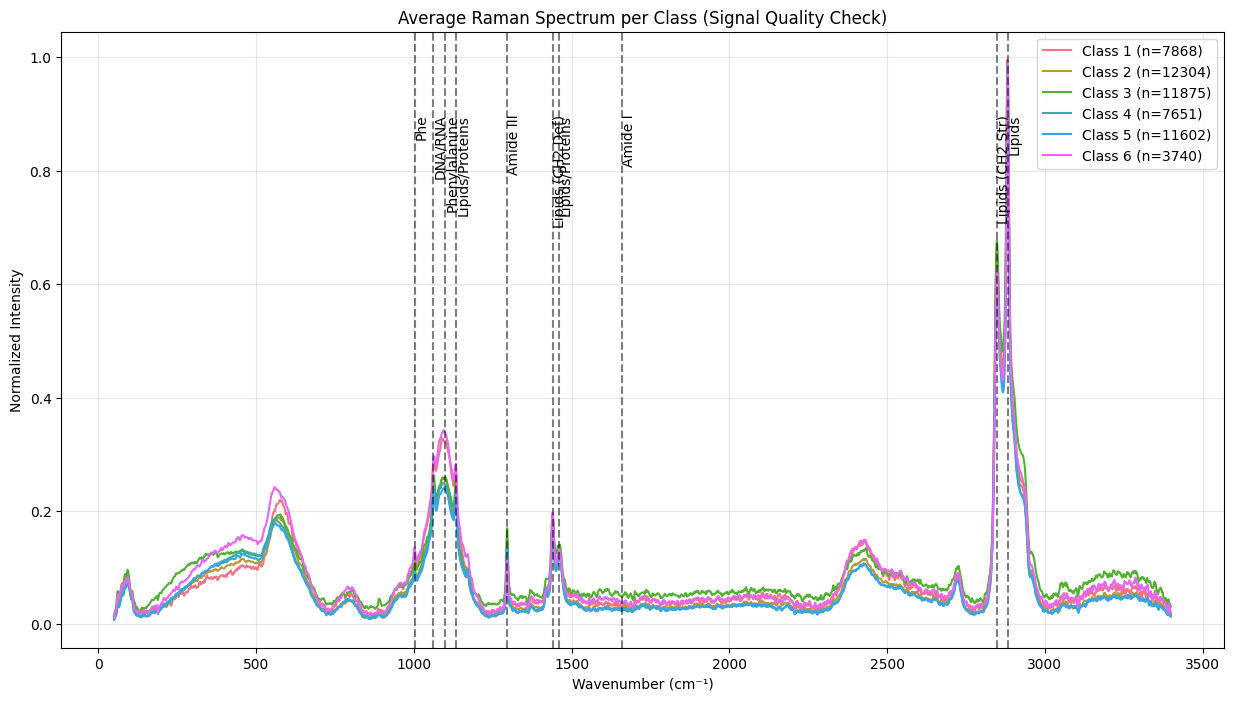

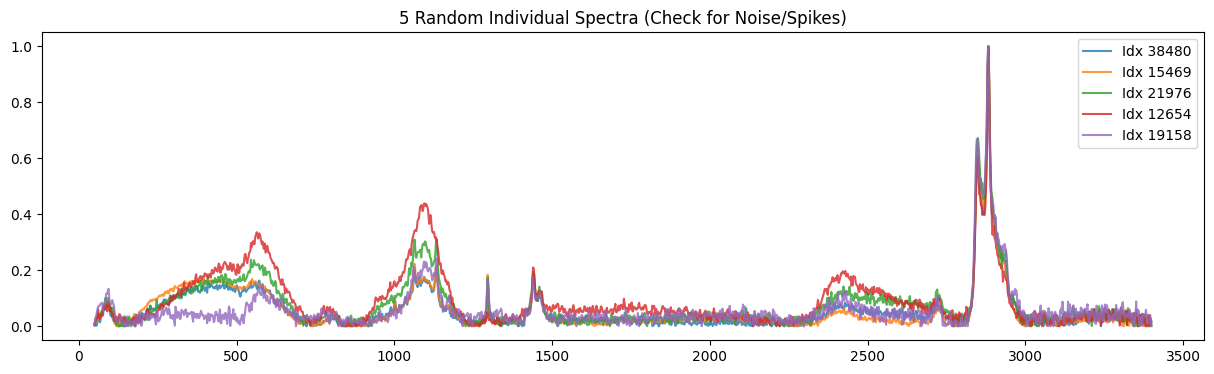

In [13]:
# --- 🚀 DATA QUALITY CHECKS ---
import h5py
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/processed/glioma_dataset_v5.h5"

with h5py.File(DATA_PATH, 'r') as f:
    X = f['spectra'][:]
    y = f['y_class'][:]
    wn = f['wavenumbers'][:]

print(f"📉 Dataset Shape: {X.shape}")
print(f"📊 Class Counts: {np.bincount(y)}")

# --- 1. Global Statistics Check ---
print("\n--- Signal Statistics ---")
print(f"Max Value in Dataset: {np.max(X):.4f} (Should be 1.0)")
print(f"Min Value in Dataset: {np.min(X):.4f} (Should be 0.0)")
print(f"Mean Value: {np.mean(X):.4f}")
print(f"Zero-Signal Spectra: {np.sum(np.max(X, axis=1) == 0)} (Should be 0)")

# --- 2. Plot Class Averages (The "fingerprint") ---
unique_classes = np.unique(y)
colors = sns.color_palette("husl", len(unique_classes))

plt.figure(figsize=(15, 8))
print("\n--- Computing Class Means ---")

for i, cls in enumerate(unique_classes):
    # Get all spectra for this class
    class_spectra = X[y == cls]
    
    # Calculate Mean and Std
    mean_spec = np.mean(class_spectra, axis=0)
    std_spec = np.std(class_spectra, axis=0)
    
    # Plot Mean
    plt.plot(wn, mean_spec, color=colors[i], label=f'Class {cls+1} (n={len(class_spectra)})', linewidth=1.5)
    
    # Optional: Shade std deviation (can be messy if overlapping, maybe skip for clarity)
    # plt.fill_between(wn, mean_spec - 0.2*std_spec, mean_spec + 0.2*std_spec, color=colors[i], alpha=0.1)

plt.title("Average Raman Spectrum per Class (Signal Quality Check)")
plt.xlabel("Wavenumber (cm⁻¹)")
plt.ylabel("Normalized Intensity")
plt.legend()
plt.grid(True, alpha=0.3)

# Add vertical lines for key biological markers
markers = {
    1004: "Phe",
    1060: "DNA/RNA",
    1100: "Phenylalanine",
    1135: "Lipids/Proteins",
    1295: "Amide III",
    1440: "Lipids (CH2 Def)",
    1460: "Lipids/Proteins",
    1660: "Amide I",
    2850: "Lipids (CH2 Str)",
    2882: "Lipids"
}
for w, name in markers.items():
    plt.axvline(w, color='black', linestyle='--', alpha=0.5)
    plt.text(w, 0.9, name, rotation=90, verticalalignment='top')

plt.show()

# --- 3. Individual Random Samples (Cosmic Ray Check) ---
# Plot 5 random raw spectra to see if they look "spiky"
plt.figure(figsize=(15, 4))
indices = np.random.choice(len(X), 5, replace=False)
for idx in indices:
    plt.plot(wn, X[idx], alpha=0.8, label=f"Idx {idx}")
plt.title("5 Random Individual Spectra (Check for Noise/Spikes)")
plt.legend()
plt.show()

The signals look fine.

📉 Dataset Shape: (258748, 1738)
📊 Class Counts: [33037 65681 45031 44185 55640 15174]

--- Signal Statistics ---
Max Value in Dataset: 1.0000 (Should be 1.0)
Min Value in Dataset: 0.0000 (Should be 0.0)
Mean Value: 0.0732
Zero-Signal Spectra: 0 (Should be 0)

Signals I see on the plot.
- 1004: Phe (Protein) -> too weak, signal present, but unreliable
- 1450: Lipids/Proteins -> slightly shifted, signal strong at 1440
- 1660: Amide I -> non existant
- 2850: Lipids (CH2) -> very strong

For other signals I see, here is the markers I plotted:
markers = {
    1004: "Phe (Protein)",
    1060: "",
    1100: "",
    1135: "",
    1295: "",
    1440: "Lipids/Proteins",
    1460: "",
    1660: "Amide I",
    2850: "Lipids (CH2)",
    2882: ""
}

Give me the code to find the values for those markers for each class average that I plotted (I can't simply do X[wn], as wn is a separate array), and I'll paste here the actual values, per class. Notice the avg is 0.07, we can use 1500-2300 as the baseline rather than full spectrum avg as that region is completely flat, only some gaussian noise there. We can use the numbers of those marker peaks and avg of the region 1500-2300 to describe most of the plot. There are some smaller peaks here and there, the CNN will figure it out if they are important or not.

In [14]:
import h5py
import numpy as np
import pandas as pd

DATA_PATH = "../data/processed/glioma_dataset_v5.h5"

# Your markers
markers = {
    1004: "Phe",
    1060: "DNA/RNA",
    1100: "Phenylalanine",
    1135: "Lipids/Proteins",
    1295: "Amide III",
    1440: "Lipids (CH2 Def)",
    1460: "Lipids/Proteins",
    1660: "Amide I",
    2850: "Lipids (CH2 Str)",
    2882: "Lipids"
}

results = []

with h5py.File(DATA_PATH, 'r') as f:
    X = f['spectra'][:]
    y = f['y_class'][:]
    wn = f['wavenumbers'][:]

    # 1. Find indices for markers
    marker_indices = {}
    for w_target, label in markers.items():
        # Find index of wavenumber closest to target
        idx = np.argmin(np.abs(wn - w_target))
        actual_w = wn[idx]
        marker_indices[label + f" ({w_target})"] = idx

    # 2. Find indices for baseline region (1500-2300)
    # Note: You mentioned 1500-2300, but Amide I is at 1660. 
    # Usually the "Silent Region" is ~1800-2800. 
    # Based on your plot observation, I will use 2000-2200 as a safe silent baseline.
    idx_base_start = np.argmin(np.abs(wn - 2000))
    idx_base_end = np.argmin(np.abs(wn - 2200))

    # 3. Calculate Stats per Class
    unique_classes = np.unique(y)
    
    for cls in unique_classes:
        # Get class mean spectrum
        class_mean = np.mean(X[y == cls], axis=0)
        
        # Calculate Baseline (Noise Floor)
        baseline_val = np.mean(class_mean[idx_base_start:idx_base_end])
        
        # Store Data
        row = {
            "Class": f"LGm-{cls+1}", 
            "Baseline (2000-2200)": baseline_val
        }
        
        # Add Marker Intensities
        for label, idx in marker_indices.items():
            row[label] = class_mean[idx]
            
        results.append(row)

# 4. Create and Print DataFrame
df_peaks = pd.DataFrame(results)
# Reorder columns to put Baseline first
cols = ["Class", "Baseline (2000-2200)"] + [c for c in df_peaks.columns if c not in ["Class", "Baseline (2000-2200)"]]
df_peaks = df_peaks[cols]

print("=== Peak Intensities per Class (Mean) ===")
print(df_peaks.to_string(index=False))

# Optional: Print raw csv format for easy copying
print("\n--- CSV Format ---")
print(df_peaks.to_csv(index=False))

=== Peak Intensities per Class (Mean) ===
Class  Baseline (2000-2200)  Phe (1004)  DNA/RNA (1060)  Phenylalanine (1100)  Lipids/Proteins (1135)  Amide III (1295)  Lipids (CH2 Def) (1440)  Lipids/Proteins (1460)  Amide I (1660)  Lipids (CH2 Str) (2850)  Lipids (2882)
LGm-1              0.047223    0.110681        0.277844              0.321846                0.235001          0.137429                 0.189499                0.127695        0.028933                 0.624343       0.944929
LGm-2              0.036360    0.095204        0.232293              0.256700                0.217092          0.143206                 0.183181                0.121968        0.028153                 0.644438       0.985821
LGm-3              0.058500    0.111735        0.242467              0.259758                0.218702          0.169694                 0.196310                0.139387        0.048274                 0.659561       0.962333
LGm-4              0.031088    0.089268        0.226388   

In [11]:
# --- 🚀 CNN SMOKE TEST (5k Samples) ---
import numpy as np
from sklearn.utils import resample
from src.models.cnn import build_1d_cnn

print("🧪 Starting CNN SMOKE TEST...")

# 1. Get One Fold of Data
for split_data in loader:
    X_train_full, y_train_full = split_data['train']
    X_val, y_val = split_data['val']
    
    # 2. Subsample 5k for speed
    X_train_small, y_train_small = resample(
        X_train_full, y_train_full, n_samples=5000, 
        replace=False, stratify=y_train_full, random_state=42
    )
    
    print(f"   Train Shape: {X_train_small.shape}")
    
    # 3. Build & Train CNN
    # Reshape for CNN: (N, 1738) -> (N, 1738, 1)
    X_train_cnn = X_train_small.reshape(-1, 1738, 1)
    X_val_cnn = X_val.reshape(-1, 1738, 1)
    
    model = build_1d_cnn(input_shape=(1738, 1), num_classes=6)
    
    history = model.fit(
        X_train_cnn, y_train_small,
        validation_data=(X_val_cnn, y_val),
        epochs=10,        # Quick test
        batch_size=32,
        verbose=1
    )
    
    # 4. Final Result
    final_acc = history.history['val_accuracy'][-1]
    print(f"\n✅ CNN DIAGNOSTIC ACCURACY: {final_acc:.4f}")
    
    if final_acc > 0.45:
        print("🚀 SUCCESS: Deep Learning is rescuing the data!")
    else:
        print("❌ FAIL: Data is inseparable. We must re-process with higher Lambda.")
        
    break

2026-02-19 10:35:27.828135: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-02-19 10:35:38.063944: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


🧪 Starting CNN SMOKE TEST...
🔄 Using Manual Splits from: ../data/splits/manual_splits.json
   Train Shape: (5000, 1738)


2026-02-19 10:35:58.737097: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 74s 442ms/step - accuracy: 0.3548 - loss: 1.5514 - val_accuracy: 0.1671 - val_loss: 1.7840
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 70s 444ms/step - accuracy: 0.3774 - loss: 1.4979 - val_accuracy: 0.1671 - val_loss: 1.7598
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 76s 487ms/step - accuracy: 0.3930 - loss: 1.4760 - val_accuracy: 0.1671 - val_loss: 1.9687
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 72s 460ms/step - accuracy: 0.3934 - loss: 1.4647 - val_accuracy: 0.2074 - val_loss: 2.4778
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 80s 451ms/step - accuracy: 0.4148 - loss: 1.4293 - val_accuracy: 0.3213 - val_loss: 2.2058
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 76s 416ms/step - accuracy: 0.4354 - loss: 1.3890 - val_accuracy: 0.2377 - val_loss: 2.2506
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 67s 426ms/step - accuracy: 0.4642 - loss: 1.3363 - val_accuracy: 0.2521 - val_loss: 1.8270
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 70s 445ms/step - accuracy: 0.4854 - loss: 1

🧠 Starting Probabilistic Data Purification...
   Data shape: (20000, 1738)
   🔄 Running PCA...
   🎭 Fitting Gaussian Mixture Model (2 Hidden States)...
      -> State 0: 15143 pixels (75.7%)
      -> State 1: 4857 pixels (24.3%)

--- Testing Hidden State 0 ---
   ✅ STATE 0 ACCURACY: 0.7273

--- Testing Hidden State 1 ---
   ✅ STATE 1 ACCURACY: 0.8436


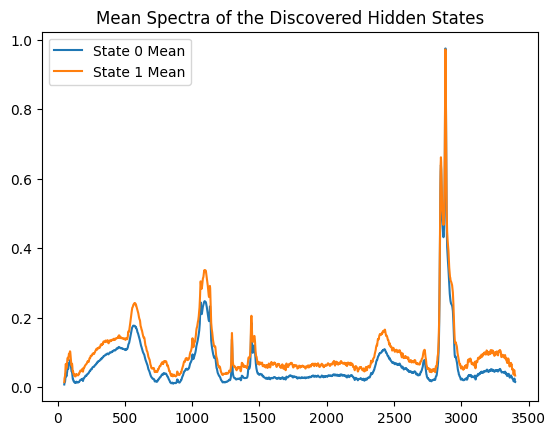

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

print("🧠 Starting Probabilistic Data Purification...")

# 1. Grab a representative sample (20k spectra)
X_all = loader.X[:]
y_all = loader.y_class[:]

# Subsample for speed
np.random.seed(42)
idx = np.random.choice(len(X_all), 20000, replace=False)
X_sub = X_all[idx]
y_sub = y_all[idx]

print(f"   Data shape: {X_sub.shape}")

# 2. Dimensionality Reduction (Crucial for GMMs to work well)
print("   🔄 Running PCA...")
pca = PCA(n_components=20, random_state=42)
X_pca = pca.fit_transform(X_sub)

# 3. Probabilistic Mixture Model (Your PGM idea)
# We assume 2 hidden states: State 0 (Healthy?), State 1 (Tumor?)
print("   🎭 Fitting Gaussian Mixture Model (2 Hidden States)...")
gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
hidden_states = gmm.fit_predict(X_pca)

# Let's see how it split the data
n_state_0 = np.sum(hidden_states == 0)
n_state_1 = np.sum(hidden_states == 1)
print(f"      -> State 0: {n_state_0} pixels ({n_state_0/len(hidden_states):.1%})")
print(f"      -> State 1: {n_state_1} pixels ({n_state_1/len(hidden_states):.1%})")

# 4. The Moment of Truth: Evaluate both states
for state in [0, 1]:
    print(f"\n--- Testing Hidden State {state} ---")
    
    # Isolate data for this state
    X_state = X_sub[hidden_states == state]
    y_state = y_sub[hidden_states == state]
    
    if len(X_state) < 1000:
        print("   Too few samples to test.")
        continue
        
    # Split train/val
    X_tr, X_v, y_tr, y_v = train_test_split(X_state, y_state, test_size=0.2, random_state=42, stratify=y_state)
    
    # Train Fast RF
    clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    clf.fit(X_tr, y_tr)
    
    # Evaluate
    acc = accuracy_score(y_v, clf.predict(X_v))
    print(f"   ✅ STATE {state} ACCURACY: {acc:.4f}")

    # Plot the mean spectrum of this state to see what it physically is
    plt.plot(wn, np.mean(X_state, axis=0), label=f'State {state} Mean')

plt.title("Mean Spectra of the Discovered Hidden States")
plt.legend()
plt.show()

## 3. Run Benchmark (5-Fold CV)

In [ ]:
fold_results = []
feature_masks = []

print("Starting Apollo Baseline Reproduction...")
print("-" * 60)

for fold_data in loader.get_cross_validation_generator():
    fold_id = fold_data['fold']
    print(f"\n>>> Running {fold_id} <<<")
    
    # Unpack Data
    X_train, y_train, _ = fold_data['train']
    X_val, y_val, _ = fold_data['val']
    
    # Print fold stats
    print(f"    Train Samples: {X_train.shape[0]} | Val Samples: {X_val.shape[0]}")
    print(f"    Held-out Patients: {np.unique(fold_data['val_sample_ids'])}")
    
    # Initialize Model
    model = ApolloPipeline(n_features=20, random_state=42)
    
    # Train
    model.fit(X_train, y_train)
    
    # Save the selected features (Critical for Phase 3: TSTR)
    # We will need to force the Synthetic SVM to use THESE SAME FEATURES later.
    feature_masks.append(model.selected_indices_)
    
    # Predict
    y_pred = model.predict(X_val)
    
    # Evaluate
    acc = accuracy_score(y_val, y_pred)
    print(f"    > Fold Accuracy: {acc:.4f}")
    
    # Store detailed results
    fold_results.append({
        'fold': fold_id,
        'accuracy': acc,
        'y_true': y_val,
        'y_pred': y_pred
    })

print("-" * 60)
print("Benchmark Complete.")

Starting Apollo Baseline Reproduction...
------------------------------------------------------------
Loading frozen splits from ../data/splits/manual_splits.json
DEBUG: Split asks for 'HF-2544_V1B_1.h5_3'
DEBUG: Loader has 'HF-305_v4b_1_1.h5_6'

>>> Running fold_0 <<<
    Train Samples: 240035 | Val Samples: 54675
    Held-out Patients: ['HF-1002_V1AT_1.h5_0' 'HF-1002_V2AT_1.h5_1' 'HF-2104_#5_1.h5_0'
 'HF-2104_#9_1.h5_1' 'HF-2104_V1T_1.h5_2' 'HF-305_v4b_1_1.h5_6'
 'HF-442_V4BB_1.h5_12' 'HF-448_V5B_1.h5_3' 'HF-592_V3T_1.h5_4'
 'HF-615_V5BB_1.h5_9' 'HF-682_V3AT_1.h5_9' 'HF-682_V3BB_1.h5_10'
 'HF-894_9_1.h5_11' 'HF-894_V1BB_1.h5_12']
  [Apollo] Fitting RF Selector on (240035, 1738)...
  [Apollo] Selected 20 features.
  [Apollo] Fitting SVM Classifier...


## 4. Analysis & Reporting

In [ ]:
# Aggregate Accuracy
accuracies = [r['accuracy'] for r in fold_results]
mean_acc = np.mean(accuracies)
std_acc = np.std(accuracies)

print(f"\n=== Final Results ===")
print(f"Apollo Baseline Accuracy: {mean_acc:.4f} (+/- {std_acc:.4f})")

# Save Baseline Metrics for future comparison
results_clean = []
for r in fold_results:
    # Create a copy without the heavy arrays
    row_clean = {k: v for k, v in r.items() if k not in ['y_true', 'y_pred']}
    results_clean.append(row_clean)

# Save Clean Metrics
results_df = pd.DataFrame(results_clean)
results_df.to_csv("../results/baseline_metrics.csv", index=False)
print("✅ Saved clean metrics CSV.")

# Save Full Predictions separately (Pickle)
import pickle
with open("../results/baseline_predictions.pkl", "wb") as f:
    pickle.dump(fold_results, f)
print("✅ Saved detailed predictions to .pkl")

### Confusion Matrix (Aggregated)

In [ ]:
all_true = np.concatenate([r['y_true'] for r in fold_results])
all_pred = np.concatenate([r['y_pred'] for r in fold_results])

cm = confusion_matrix(all_true, all_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f"Aggregated Confusion Matrix (Acc: {mean_acc:.4f})")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.show()